# DS111 · Mean, Median, Mode khi điền khuyết

**Câu hỏi.** Kiểu biến, hình dạng phân phối, ngoại lệ và mục tiêu đánh giá ảnh hưởng thế nào đến lựa chọn một giá trị điền?

Notebook tự sinh lại dữ liệu, hình và bảng từ seed 42. Dữ liệu đầy đủ là **ground truth** chỉ dùng làm chuẩn so sánh. Phần EDA mô tả một bảng quan sát ở mức thiếu danh nghĩa 15%. Benchmark lấy một lần chia train/test riêng để chấm trên ô test bị che.

Bối cảnh môn học dựa trên mô tả slide 14–17 của `Bai04_EDA.pdf` trong đặc tả. Không lấy được PDF gốc qua liên kết Drive. Xem phần mở rộng và các nguồn ở [references.md](../presentation/references.md).

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.impute import SimpleImputer

current = Path.cwd()
root = next(
    (p for p in (current, *current.parents) if (p / "src" / "run_experiments.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở notebook trong project hoặc đặt thư mục làm việc tại project.")
sys.path.insert(0, str(root))
from src.generate_data import CATEGORY, NUMERIC, demo_data, generate_complete
from src.run_experiments import describe_demo, run

def figure(name):
    display(Image(filename=str(root / "figures" / f"{name}.png"), width=900))

evidence = run(root)
complete = generate_complete()
observed, demo_mask = demo_data(complete)
print(f"Số hàng: {len(complete):,}. Số cột phân tích: {demo_mask.shape[1]}.")

Số hàng: 3,200. Số cột phân tích: 4.


## 1. Thiếu dữ liệu và phân tích đơn biến

`NaN`, `None` hoặc `pd.NA` biểu thị thiếu trong các kiểu dữ liệu khác nhau. Tài liệu miền quyết định chuỗi rỗng, `?`, `-999` có cần chuẩn hóa hay không. Giá trị 0 có thể là quan sát hợp lệ. Thiếu có thể đến từ bỏ trống câu hỏi, thiết bị lỗi, nhập liệu hoặc câu hỏi không áp dụng. Tính tỷ lệ thiếu cột $j$ bằng $m_j/N$. Nhiều phép tóm tắt bỏ qua NaN, từ đó có thể làm lệch mẫu dùng để suy luận.

Bộ sinh gồm biến tam giác đối xứng, biến lognormal, biến hai cụm theo A/B và nhãn M/S/L. Giữ nhóm A/B quan sát đầy đủ. Che Bernoulli độc lập với giá trị (MCAR). Với MAR, xác suất thiếu có thể phụ thuộc phần quan sát. Với MNAR, phần chưa quan sát vẫn ảnh hưởng sau khi xét phần quan sát. Biểu đồ và tỷ lệ thiếu chỉ cung cấp dấu hiệu để đặt câu hỏi về cơ chế.

,số ô thiếu,tỷ lệ thiếu
symmetric_numeric,481,15.03%
skewed_numeric,474,14.81%
multimodal_numeric,488,15.25%
category,468,14.62%
group,0,0.00%


,count,mean,median,mode,std,min,max,skewness,iqr_flag_count
variable,,,,,,,,,
symmetric_numeric,2719.0,49.835,49.910,,8.198,30.674,69.567,0.036,0.0
skewed_numeric,2726.0,23.508,16.004,,23.554,0.394,258.545,3.410,183.0
multimodal_numeric,2712.0,49.970,49.813,,15.623,22.219,81.103,-0.006,0.0


,tần suất
category,
M,1654
S,735
L,343


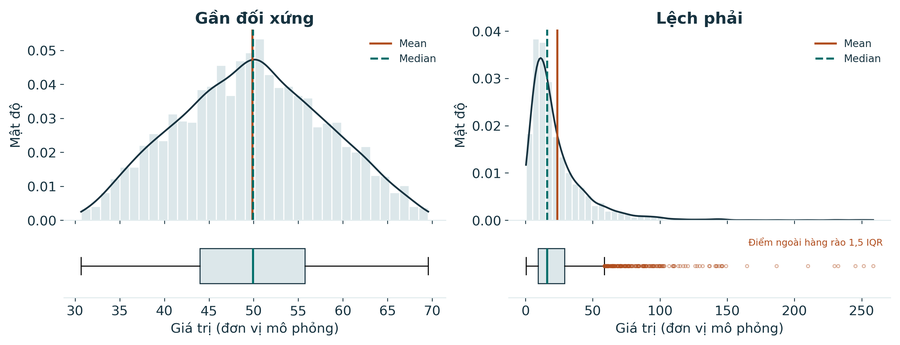

In [2]:
missing = pd.DataFrame({"số ô thiếu": observed.isna().sum(), "tỷ lệ thiếu": observed.isna().mean()})
display(missing.style.format({"tỷ lệ thiếu": "{:.2%}"}))
eda = pd.DataFrame(evidence["eda"]).set_index("variable")
display(eda[["count", "mean", "median", "mode", "std", "min", "max", "skewness", "iqr_flag_count"]].round(3))
display(observed[CATEGORY].value_counts().rename("tần suất").to_frame())
figure("eda_numeric")

Đọc histogram và boxplot cùng nhau. Trên biến gần đối xứng, hai đường Mean và Median gần nhau và hàng rào 1,5 IQR không gắn cờ điểm nào. Trên biến lognormal, đuôi kéo sang phải, Mean cao hơn Median và boxplot gắn cờ nhiều điểm. Các điểm đuôi là giá trị do mô hình sinh ra. Hàng rào 1,5 IQR là cách gắn cờ để xem xét, chưa phải phán quyết về lỗi dữ liệu.

## 2. Chọn thống kê thay thế theo kiểu biến và mục tiêu

- **Mean** $\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i$ dùng mọi độ lớn quan sát. Khi một quan sát đổi thêm $\Delta$, Mean đổi $\Delta/n$.
- **Median** là vị trí giữa sau khi sắp xếp. Với $n$ chẵn lấy trung bình hai vị trí giữa. Thứ hạng giúp Median bền hơn trước giá trị cực đoan.
- **Mode** là giá trị có tần suất cực đại. Với dữ liệu liên tục, đỉnh mật độ hoặc khoảng histogram có thể hữu ích hơn phép đếm trùng khớp. Nhiều giá trị có thể đồng hạng.

Ký hiệu đuôi điển hình là skewness dương cho đuôi phải và âm cho đuôi trái. Thứ tự trên hình là tính chất của các phân phối minh họa cụ thể. Đối xứng còn có thể gặp ở tam giác và hỗn hợp hai cụm. Xem thêm [NIST về skewness](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35b.htm).

| Bằng chứng quan sát | Phương pháp nên thử | Vì sao và cần kiểm chứng gì |
|---|---|---|
| Định lượng gần đối xứng, ít ngoại lệ | Mean | Dùng độ lớn của mọi quan sát. Kiểm tra miền giá trị và RMSE. |
| Định lượng lệch hoặc nhiều điểm cực đoan | Median | Bền theo thứ hạng. Kiểm tra MAE, RMSE và đỉnh nhân tạo. |
| Định tính | Mode | Nhãn phổ biến nhất. Kiểm tra đa Mode và lớp hiếm. |
| Nhóm quan sát được, phân phối khác nhau | Thống kê theo nhóm | Giữ sự khác biệt có ý nghĩa. Kiểm tra nhóm hiếm, cột nhóm và leakage. |
| Nhiều đỉnh hoặc đồng hạng Mode | Phân tích cấu trúc trước | Cân nhắc thống kê có điều kiện và công bố quy tắc hòa. |

Đây là các điểm bắt đầu. Chọn theo ngữ nghĩa, biểu đồ, mức độ thiếu và mục tiêu, thay vì đặt ngưỡng skewness hoặc tỷ lệ thiếu chung.

Age: Mean = 34, Median = 23.
Size: Mode = ['M'].
Đa Mode: [2, 8], Mean = 4.6, Median = 3.


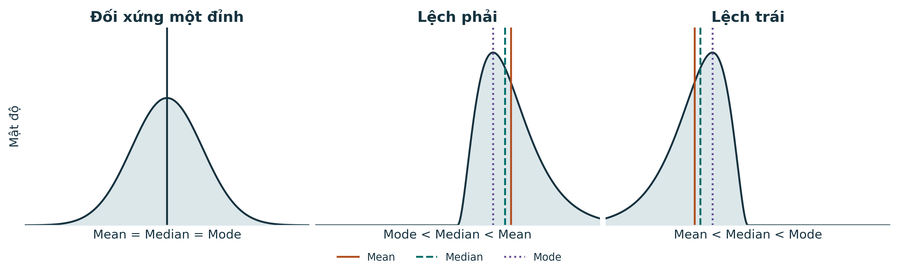

In [3]:
figure("distribution_theory")
age = pd.Series([20, 22, 23, 25, 80, np.nan])
size = pd.Series(["M", "M", "L", "S", np.nan, "M"])
tie = pd.Series([2, 2, 3, 8, 8, np.nan])
print(f"Age: Mean = {age.mean():g}, Median = {age.median():g}.")
print(f"Size: Mode = {size.mode().tolist()}.")
print(f"Đa Mode: {tie.mode().astype(int).tolist()}, Mean = {tie.mean():g}, Median = {tie.median():g}.")

Tuổi 80 cao so với cụm 20–25 trong mẫu nhỏ này và có thể là quan sát hợp lệ. Nếu muốn một giá trị thay thế gần cụm, 23 là một lựa chọn minh họa. Tuổi thật bị che vẫn chưa biết. Size là nhãn, nên phép cộng mã số sẽ phụ thuộc cách mã hóa. Ví dụ đa Mode có hai mốt. `most_frequent` chọn giá trị nhỏ nhất khi hòa, là một quy tắc ổn định cần công bố. [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)

## 3. Điền bằng SimpleImputer trong demo EDA

Fit từ phần quan sát của chính bảng để xem điều gì thay đổi trong bảng. Phần minh họa này phục vụ so sánh phân phối.

Mean: điền 23.50819217339764, sau điền còn 0 ô thiếu.
Median: điền 16.003544799970946, sau điền còn 0 ô thiếu.
Mode: điền M, sau điền còn 0 ô thiếu.


,stage,count,mean,median,std,variance,missing_rate
1,Complete,3200,23.6243,16.0925,23.9771,574.9008,0.0000
4,Observed,2726,23.5082,16.0035,23.5537,554.7782,0.1481
7,Mean,3200,23.5082,19.1739,21.7388,472.5760,0.0000
10,Median,3200,22.3966,16.0035,21.9017,479.6849,0.0000


stage,Complete,Mode,Observed
category,,,
L,401,343,343
M,1937,2122,1654
S,862,735,735


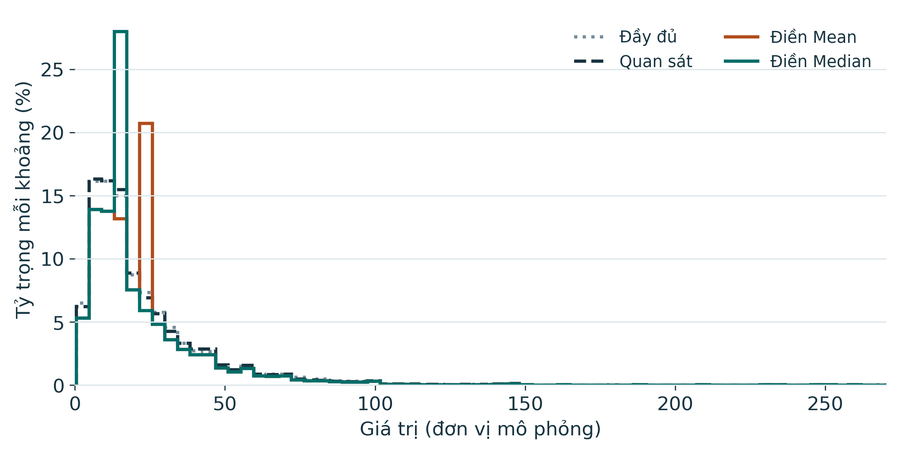

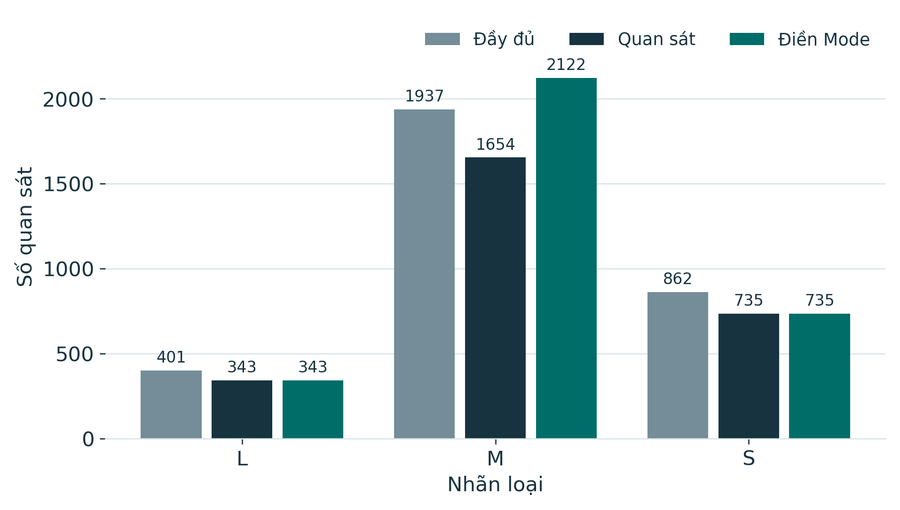

In [4]:
mean_imputer = SimpleImputer(strategy="mean")
median_imputer = SimpleImputer(strategy="median")
mode_imputer = SimpleImputer(strategy="most_frequent")
skew = NUMERIC[1]
for label, imputer, variable in [
    ("Mean", mean_imputer, skew), ("Median", median_imputer, skew), ("Mode", mode_imputer, CATEGORY),
]:
    result = imputer.fit_transform(observed[[variable]])
    print(f"{label}: điền {imputer.statistics_[0]}, sau điền còn {pd.isna(result).sum()} ô thiếu.")

stages, distribution, category_frequencies = describe_demo(complete, observed)
display(distribution.query("variable == @skew").drop(columns=["variable", "corr_group_B"]).round(4))
display(category_frequencies.pivot(index=CATEGORY, columns="stage", values="count"))
figure("numeric_imputation_before_after")
figure("categorical_mode")

Mean giữ Mean quan sát trong demo vì mọi ô điền có độ lệch bằng 0 so với Mean đó. Với $n$ ô quan sát và $m$ ô điền, phương sai mẫu trở thành $s^2_{\rm obs}(n-1)/(n+m-1)$ khi $n\ge2$. Công thức này so sánh với phần quan sát đã dùng để tính Mean. Mean từ train có thể khác Mean quan sát của test. Median và Mode cũng tạo một điểm tập trung nhân tạo. Khi điền một hằng số toàn cục, mối liên hệ với biến nhóm có thể suy yếu.

## 4. Benchmark trên ô test bị che

1. Chia 75/25 theo hàng từ dữ liệu đầy đủ.
2. Với mỗi mức 5%, 15%, 30%, tạo 12 bộ mặt nạ train và test từ hai luồng RNG độc lập. Mỗi cặp phương pháp dùng cùng mặt nạ.
3. Fit trên train đã che rồi transform test đã che. Chỉ lấy ground truth ở ô test có mask True.
4. Với $k$ ô test che và $e_i=\hat{x}_i-x_i$, MAE là $\sum|e_i|/k$, RMSE là $\sqrt{\sum e_i^2/k}$. Với nhãn, Accuracy là số khớp chia cho $k$.

SD đi kèm điểm trung bình đo sự dao động theo mặt nạ, trên cùng lần chia. Sai số điểm thấp không bảo đảm bảo toàn hình dạng hoặc liên hệ giữa các biến. [scikit-learn về data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)

metric                                    Accuracy           MAE          RMSE
variable           method                                                     
category           Mode          60.56% ± 3.19 đpt             —             —
multimodal_numeric Group Median                  —   3.12 ± 0.20   3.90 ± 0.25
                   Mean                          —  14.88 ± 0.33  15.38 ± 0.35
                   Median                        —  14.75 ± 0.46  16.13 ± 0.68
skewed_numeric     Mean                          —  16.50 ± 2.22  25.83 ± 6.15
                   Median                        —  15.87 ± 2.40  27.55 ± 6.38
symmetric_numeric  Mean                          —   6.67 ± 0.34   8.20 ± 0.38
                   Median                        —   6.68 ± 0.34   8.21 ± 0.38

missing_rate                                0.05    0.15    0.30
variable           method       metric                          
category           Mode         Accuracy   0.562   0.606   0.616
multimodal_numeric Group Median MAE        3.231   3.123   3.196
                                RMSE       4.011   3.902   3.994
                   Mean         MAE       14.900  14.879  14.964
                                RMSE      15.426  15.378  15.486
                   Median       MAE       14.809  14.751  14.933
                                RMSE      16.017  16.126  16.399
skewed_numeric     Mean         MAE       16.750  16.499  16.115
                                RMSE      24.728  25.834  25.783
                   Median       MAE       16.092  15.873  15.279
                                RMSE      26.535  27.548  27.304
symmetric_numeric  Mean         MAE        6.439   6.672   6.524
                                RMSE       7.992   8.201   8.048
                   Median       MAE        6.446   6.677   6.528
                                RMSE       8.002   8.209   8.055

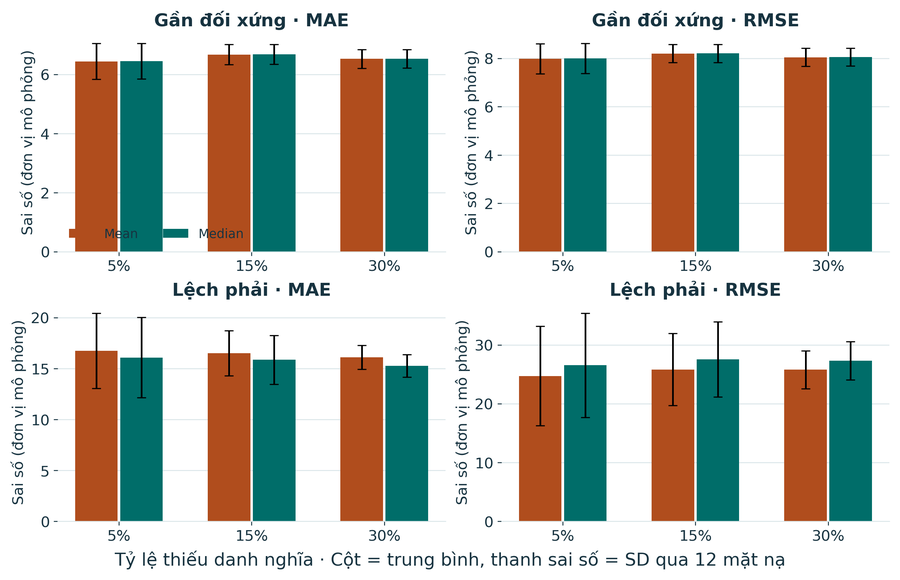

In [5]:
scores = pd.DataFrame(evidence["scores"])
focus = scores.loc[scores.missing_rate.eq(0.15)].copy()
focus["mean ± SD"] = focus.apply(
    lambda r: f"{r['mean']:.2%} ± {r['std'] * 100:.2f} đpt" if r["metric"] == "Accuracy"
    else f"{r['mean']:.2f} ± {r['std']:.2f}", axis=1,
)
display(focus.pivot(index=["variable", "method"], columns="metric", values="mean ± SD").fillna("—"))
display(scores.pivot_table(index=["variable", "method", "metric"], columns="missing_rate", values="mean").round(3))
figure("imputation_errors")

Với cùng một hằng số, tối thiểu hóa sai số tuyệt đối dẫn đến Median trên tập dùng để tối ưu. Tối thiểu hóa bình phương sai số dẫn đến Mean. Với train đại diện cho các ô bị che kiểu MCAR, đây là cách giải thích hai thứ hạng ngược chiều trên biến lệch phải. Ở biến gần đối xứng, hai lựa chọn cho điểm gần nhau. Accuracy của Mode phản ánh tỷ lệ nhãn đa số, còn những ô thật sự thuộc lớp khác đều nhận sai nhãn.

## 5. Hai cụm và giới hạn

Hai đỉnh tương ứng với nhóm A/B được sinh theo thiết kế. Nếu nhóm có sẵn lúc áp dụng, có thể tính Median theo nhóm từ train và dùng Median train toàn cục cho nhóm chưa gặp hoặc dưới 20 quan sát. Điều kiện theo nhóm chỉ có ích khi nhóm mang thông tin liên quan, đủ dữ liệu và được quan sát đúng thời điểm.

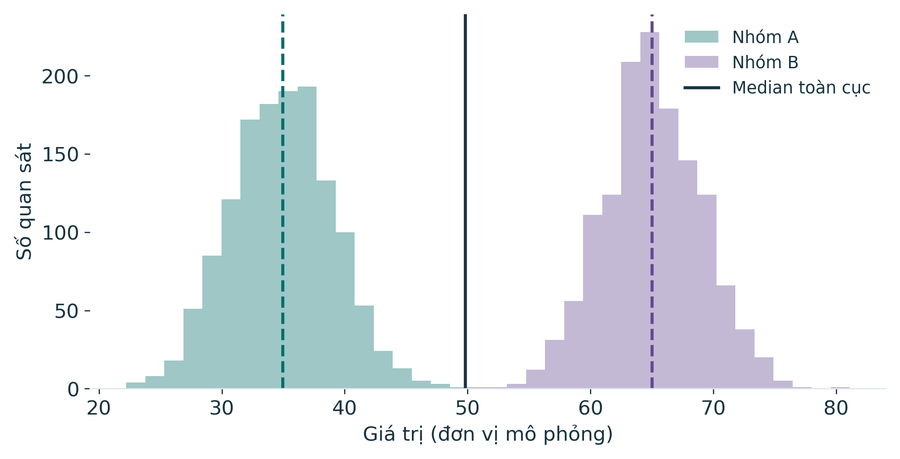

,stage,mean,median,std,corr_group_B
2,Complete,49.8472,45.3439,15.6228,0.9655
5,Observed,49.9704,49.8134,15.6225,0.9653
8,Mean,49.9704,49.9704,14.3816,0.8887
11,Median,49.9464,49.8134,14.3818,0.8888


In [6]:
figure("multimodal_groups")
multi = NUMERIC[2]
display(distribution.loc[distribution.variable.eq(multi), ["stage", "mean", "median", "std", "corr_group_B"]].round(4))

**Kết luận.** Xác định kiểu biến và cơ chế thiếu khả dĩ, kiểm tra phân phối trước khi chọn thống kê, rồi đánh giá cả sai số và biến dạng sau khi điền. Giá trị điền là một ước lượng. Khi dữ liệu thiếu có hệ thống, mỗi nhóm thiếu nhiều hoặc cần suy luận bất định, nên kiểm tra độ nhạy và cân nhắc phương pháp có điều kiện hoặc multiple imputation. Benchmark này giới hạn ở bộ sinh và các mặt nạ MCAR đã mô tả.